# ToysAD-8K DS1 LocateAnything Prompt Freeze

**Notebook file:** `04.3-toysad8k-ds1-locateanything-prompt-freeze.ipynb`

This notebook compares two short, generic prompts for the automatic object proposal route. It reuses the completed `object` baseline from Notebook 04.1 and runs `individual object` through LocateAnything. The model is loaded once.

The new prompt must complete a one-image check, a 20-image pilot, a measured pilot repeat, and the full 2,000-image DS1 screen. After both proposal files are complete and hash locked, the protected evaluator compares raw boxes, area and overlap filtering, and an eight-proposal outlier safeguard. The outlier cap is derived from the label-free DS1 proposal-count distribution. The selected candidate maximises F2 at box IoU 0.50, with documented tie breakers. F2 is used because a missed object is more harmful than an extra proposal that a user can remove. No fixed metric cutoff is used to select the candidate.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `04.3 DS1 LocateAnything prompt freeze`  
Clean notebook SHA-256: `ae36318efe1c8d0023405ab6cbe477dba26061f4380de0b3c3ebf6be6a3621bc`  
Downloaded saved-output SHA-256: `25be57fae598c1182f0138829bb766357736f227cd6d3956e17d27629d67400c`


## Experiment boundary

The two supported prompts are fixed before the run:

1. `object`
2. `individual object`

DS1 is development data. This notebook can choose one prompt and postprocessing policy for the next stage, but it cannot make a final performance claim. The chosen settings must be applied unchanged to DS2 confirmation data. RGB images, per-image boxes, model responses, evaluator records, and example panels stay in private Kaggle output. ClearML receives aggregate tables, charts, configuration records, and hashes only.

In [1]:
from __future__ import annotations

import json
import hashlib
import os
from pathlib import Path
import subprocess
import sys

from IPython.display import Image as DisplayImage, display
import pandas as pd

NOTEBOOK_NAME = "04.3-toysad8k-ds1-locateanything-prompt-freeze.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/working").is_dir() else "local"
default_output = (
    Path("/kaggle/temp/toysad8k_ds1_locateanything_prompt_freeze")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else Path.cwd() / ".local" / "runs" / "notebook04_3"
)
OUTPUT_ROOT = Path(os.getenv("VPI_OUTPUT_ROOT", str(default_output))).expanduser().resolve()

print(f"Environment: {EXECUTION_ENVIRONMENT}")
print(f"Notebook: {NOTEBOOK_NAME}")
print(f"Output folder: {OUTPUT_ROOT}")

Environment: kaggle
Notebook: 04.3-toysad8k-ds1-locateanything-prompt-freeze.ipynb
Output folder: /kaggle/temp/toysad8k_ds1_locateanything_prompt_freeze


## Locate the code and frozen inputs

In [2]:
def kaggle_dataset_roots() -> list[Path]:
    input_root = Path("/kaggle/input")
    if not input_root.is_dir():
        return []
    candidates: list[Path] = []
    for pattern in ("*", "datasets/*/*", "datasets/*/*/versions/*"):
        candidates.extend(path for path in input_root.glob(pattern) if path.is_dir())
    return sorted(set(candidates), key=lambda path: path.as_posix())


def find_code_root() -> Path:
    # Prefer an explicit path, then known local repository and Kaggle mount shapes.
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend([Path.cwd(), *Path.cwd().parents])
    for mounted in kaggle_dataset_roots():
        candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        marker = candidate / "src/visual_peer_inspector/workflows/locateanything_prompt_freeze_ds1.py"
        if marker.is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the Notebook 04.3 code snapshot")


def find_package(variable: str, predicate, required_entries: tuple[str, ...]) -> Path:
    # Accept a mounted package only when its own record satisfies the contract.
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    for mounted in kaggle_dataset_roots():
        candidates.append(mounted)
        candidates.extend(child for child in sorted(mounted.iterdir()) if child.is_dir())
    for candidate in candidates:
        record_path = candidate / "package_record.json"
        if not record_path.is_file():
            continue
        try:
            record = json.loads(record_path.read_text(encoding="utf-8"))
        except Exception:
            continue
        if predicate(record) and all((candidate / entry).exists() for entry in required_entries):
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate required package: {variable}")


def find_baseline_result() -> Path:
    configured = os.getenv("VPI_BASELINE_RESULTS")
    if configured:
        candidates = [Path(configured).expanduser()]
    else:
        candidates = []
        for mounted in kaggle_dataset_roots():
            for pattern in (
                "private/proposal_results.jsonl",
                "*/private/proposal_results.jsonl",
                "*/*/private/proposal_results.jsonl",
                "*/*/*/private/proposal_results.jsonl",
            ):
                candidates.extend(mounted.glob(pattern))
    matches_by_identity: dict[tuple[str, str], list[Path]] = {}
    for result_path in candidates:
        run_path = result_path.parent.parent / "safe" / "run_record.json"
        if not run_path.is_file():
            continue
        record = json.loads(run_path.read_text(encoding="utf-8"))
        if (
            record.get("stage") == "ds1_locateanything_screen"
            and record.get("status") == "completed"
            and record.get("configuration", {}).get("prompt") == "object"
            and record.get("summary", {}).get("job_count") == 2_000
        ):
            identity = (
                hashlib.sha256(result_path.read_bytes()).hexdigest(),
                hashlib.sha256(run_path.read_bytes()).hexdigest(),
            )
            matches_by_identity.setdefault(identity, []).append(result_path.resolve())
    if len(matches_by_identity) != 1:
        raise RuntimeError(
            "Expected one distinct completed Notebook 04.1 result, "
            f"found {len(matches_by_identity)}"
        )
    return sorted(next(iter(matches_by_identity.values())), key=lambda path: path.as_posix())[0]


CODE_ROOT = find_code_root()
MODEL_INPUT_ROOT = find_package(
    "VPI_MODEL_INPUT_ROOT",
    lambda record: (
        record.get("cohort_id") == "toysad8k-development-screen-100-v1"
        and record.get("release_id") == "toysad8k-train-2000-v2"
        and record.get("image_count") == 2_000
    ),
    ("neutral_corpus_manifest.jsonl", "media"),
)
EVALUATOR_ROOT = find_package(
    "VPI_EVALUATOR_ROOT",
    lambda record: record.get("package_kind") == "toysad8k-ds1-mask-evaluator",
    ("evaluator_crosswalk.jsonl", "masks"),
)
BASELINE_RESULTS = find_baseline_result()
sys.path.insert(0, str(CODE_ROOT / "src"))

display(pd.DataFrame([
    {"input": "Code snapshot", "folder": CODE_ROOT.name},
    {"input": "DS1 RGB package", "folder": MODEL_INPUT_ROOT.name},
    {"input": "DS1 evaluator package", "folder": EVALUATOR_ROOT.name},
    {"input": "Notebook 04.1 baseline", "folder": BASELINE_RESULTS.parent.parent.name},
]))

,input,folder
0,Code snapshot,vpi-code-snapshot
1,DS1 RGB package,vpi-toysad-ds1-screen100-model-input
2,DS1 evaluator package,vpi-toysad-ds1-mask-evaluator
3,Notebook 04.1 baseline,vpi-toysad-ds1-locateanything-output


## Install the pinned inference dependencies

In [3]:
if EXECUTION_ENVIRONMENT == "kaggle":
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/locateanything-lock.txt")],
        timeout=600,
    )

from visual_peer_inspector.workflows.locateanything_prompt_freeze_ds1 import (
    POSTPROCESSING_POLICIES,
    PROMPT_CANDIDATES,
    prompt_configurations,
)

configurations = prompt_configurations()
display(pd.DataFrame([
    {
        "prompt key": key,
        "prompt": prompt,
        "source": "Notebook 04.1 baseline" if key == "object" else "new model run",
        "model revision": configurations[key].model_revision,
    }
    for key, prompt in PROMPT_CANDIDATES
]))
display(pd.DataFrame({"postprocessing policy": list(POSTPROCESSING_POLICIES)}))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.5 MB/s eta 0:00:00


,prompt key,prompt,source,model revision
0,object,object,Notebook 04.1 baseline,c32291ca5e996f5a7a485845b4f57a233936bba0
1,individual_object,individual object,new model run,c32291ca5e996f5a7a485845b4f57a233936bba0


,postprocessing policy
0,raw
1,area_nms_075
2,area_nms_075_cap8


## Run the ordered gates and full DS1 screen

ClearML is not started during model inference. The command prints model-load checkpoints and progress after the first image, every 100 images, and the last image. Existing candidate result files are resumed only when their configuration and image hashes match. If a gate fails, the next stage does not start.

In [4]:
if EXECUTION_ENVIRONMENT == "kaggle":
    import torch

    if not torch.cuda.is_available():
        raise RuntimeError("Notebook 04.3 requires a Kaggle GPU")
    display(pd.DataFrame([{
        "GPU count": torch.cuda.device_count(),
        "active GPU": torch.cuda.get_device_name(0),
        "CUDA runtime": torch.version.cuda,
    }]))

command = [
    sys.executable,
    str(CODE_ROOT / "scripts/run_ds1_locateanything_prompt_freeze.py"),
    "--model-input-root", str(MODEL_INPUT_ROOT),
    "--evaluator-root", str(EVALUATOR_ROOT),
    "--baseline-results", str(BASELINE_RESULTS),
    "--output-root", str(OUTPUT_ROOT),
]
model_source = os.getenv("VPI_LOCATEANYTHING_MODEL_SOURCE")
if model_source:
    command.extend(["--model-source", model_source])

process = subprocess.Popen(
    command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)
assert process.stdout is not None
for line in process.stdout:
    print(line, end="", flush=True)
return_code = process.wait()
if return_code != 0:
    raise RuntimeError(f"Notebook 04.3 runner exited with status {return_code}")

,GPU count,active GPU,CUDA runtime
0,2,Tesla T4,12.8


{"device": "cuda", "dtype": "torch.float16", "elapsed_seconds": 23.436, "stage": "dependencies_ready"}
{"elapsed_seconds": 23.436, "source_kind": "hub", "stage": "tokenizer_load_started"}
{"elapsed_seconds": 25.688, "stage": "tokenizer_ready"}
{"elapsed_seconds": 25.688, "source_kind": "hub", "stage": "processor_load_started"}
/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(
{"elapsed_seconds": 28.973, "stage": "processor_ready"}
{"elapsed_seconds": 28.973, "source_kind": "hub", "stage": "model_weights_load_started"}
`torch_dtype` is deprecated! Use `dtype` instead!

Fetching 2 files: 100%|██████████| 2/2 [00:35<00:00, 17.80s/it]
Qwen2ForCausalLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't 

## Prompt and policy results

,candidate_key,prompt_key,prompt,postprocessing_policy,image_count,reference_count,proposal_count,matched_count_at_0_50,precision_at_0_50,recall_at_0_50,...,full_image_success_rate,count_mean_absolute_error,count_signed_bias,miss_count,extra_count,images_with_misses,images_with_extras,merge_candidate_count,split_or_duplicate_candidate_count,mean_proposals_per_image
5,individual_object__area_nms_075_cap8,individual_object,individual object,area_nms_075_cap8,2000,7700,7610,7407,0.973325,0.961948,...,0.9060,0.1300,-0.0450,293,203,164,106,82,42,3.8050
4,individual_object__area_nms_075,individual_object,individual object,area_nms_075,2000,7700,8035,7412,0.922464,0.962597,...,0.9060,0.3425,0.1675,288,623,164,106,82,98,4.0175
2,object__area_nms_075_cap8,object,object,area_nms_075_cap8,2000,7700,7572,7275,0.960777,0.944805,...,0.8825,0.1770,-0.0640,425,297,205,147,93,44,3.7860
1,object__area_nms_075,object,object,area_nms_075,2000,7700,7996,7276,0.909955,0.944935,...,0.8825,0.3890,0.1480,424,720,204,147,93,67,3.9980
3,individual_object__raw,individual_object,individual object,raw,2000,7700,9399,7412,0.788595,0.962597,...,0.9060,1.0055,0.8495,288,1987,164,121,82,205,4.6995
0,object__raw,object,object,raw,2000,7700,9249,7276,0.786680,0.944935,...,0.8825,0.9925,0.7745,424,1973,204,164,93,81,4.6245


,prompt_key,prompt,source,image_count,successful_image_count,failed_image_count,mean_proposals_per_image,median_runtime_seconds,p95_runtime_seconds,total_inference_seconds
0,object,object,reused_baseline,2000,2000,0,4.6245,0.4119,0.6277,1059.5058
1,individual_object,individual object,new_model_run,2000,2000,0,4.6995,0.4064,0.6216,1027.8051


,prompt_key,prompt,pilot_image_count,exact_box_agreement_rate
0,object,object,20,1.0
1,individual_object,individual object,20,1.0


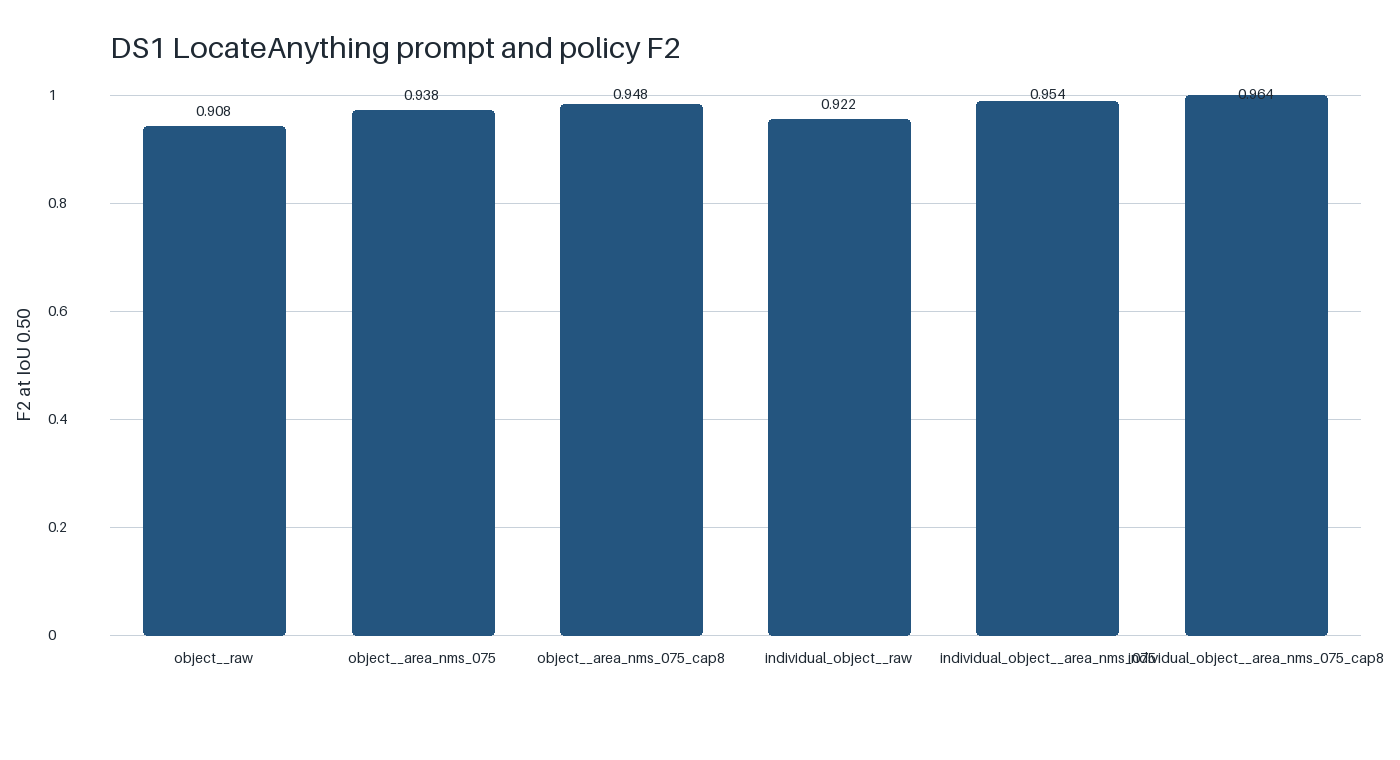

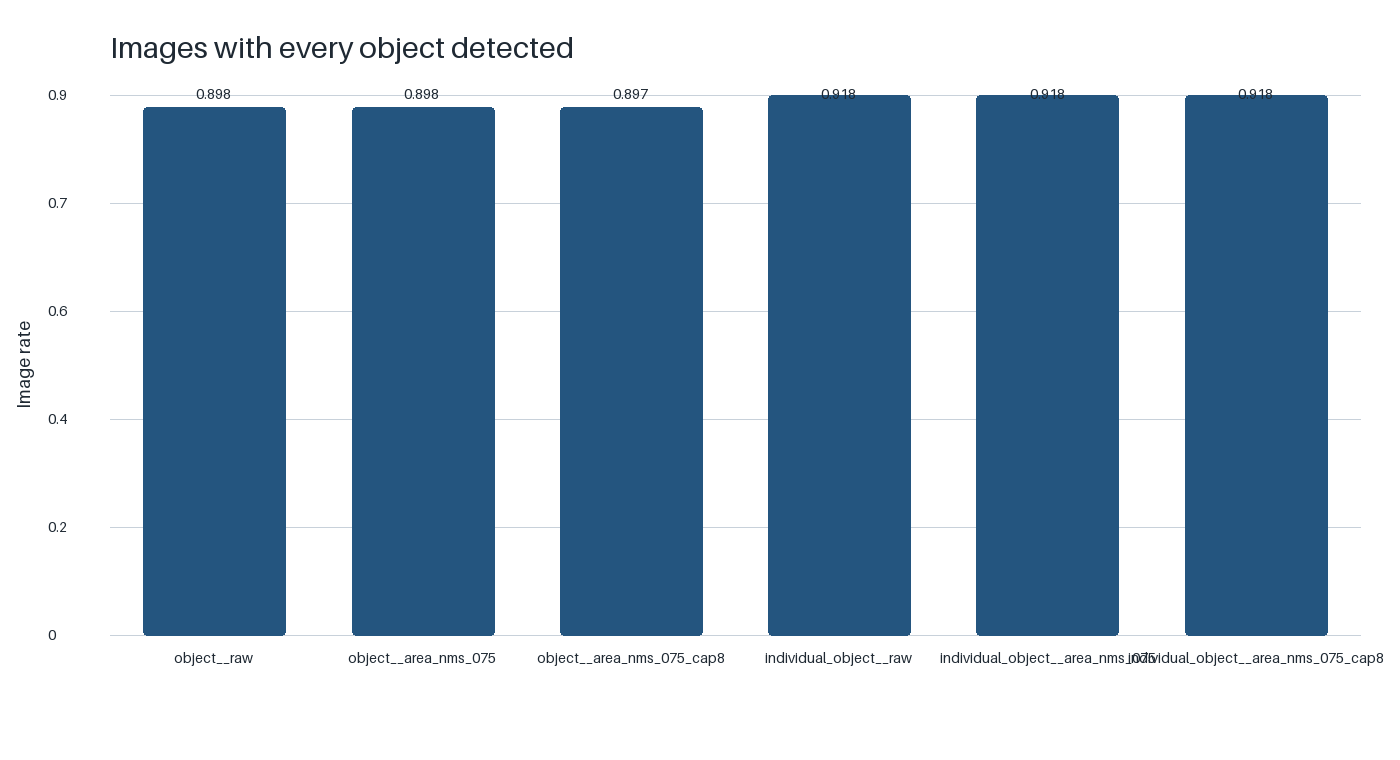

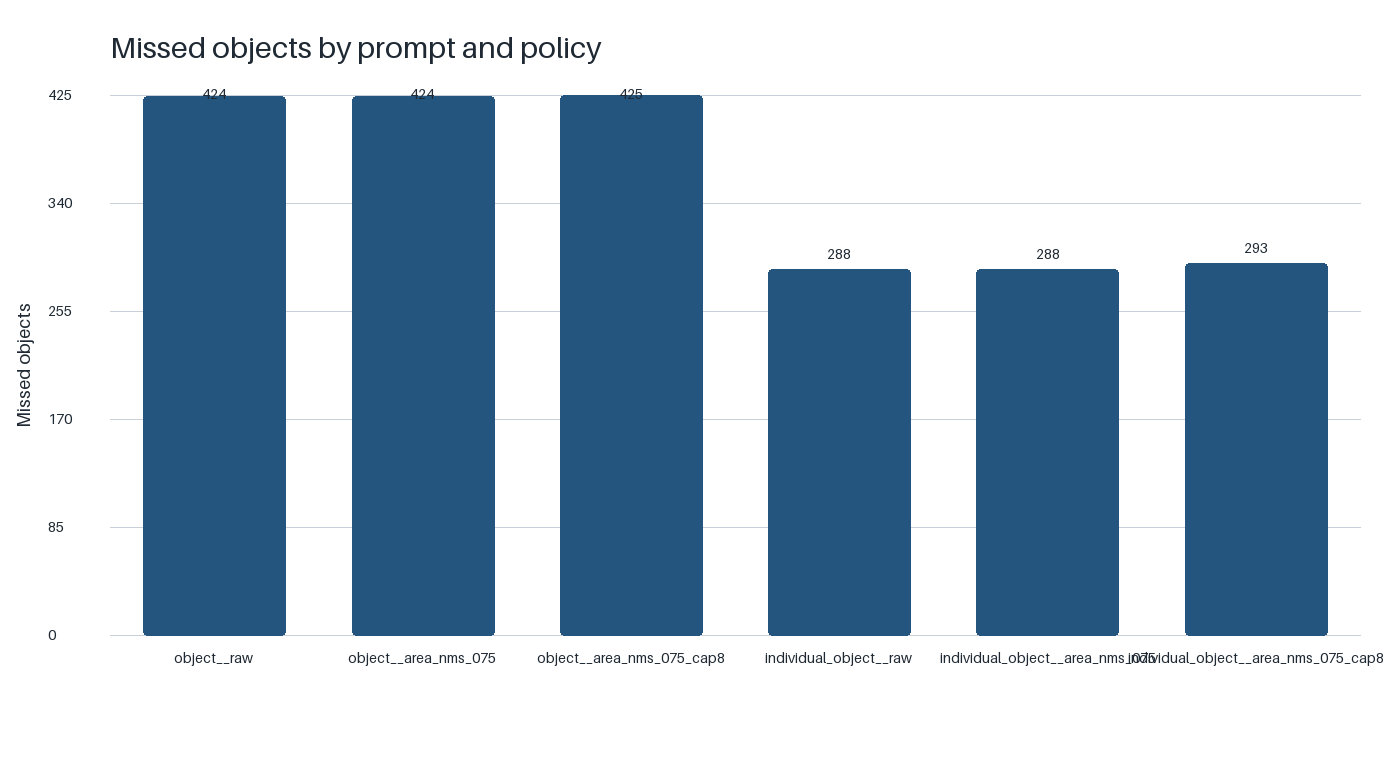

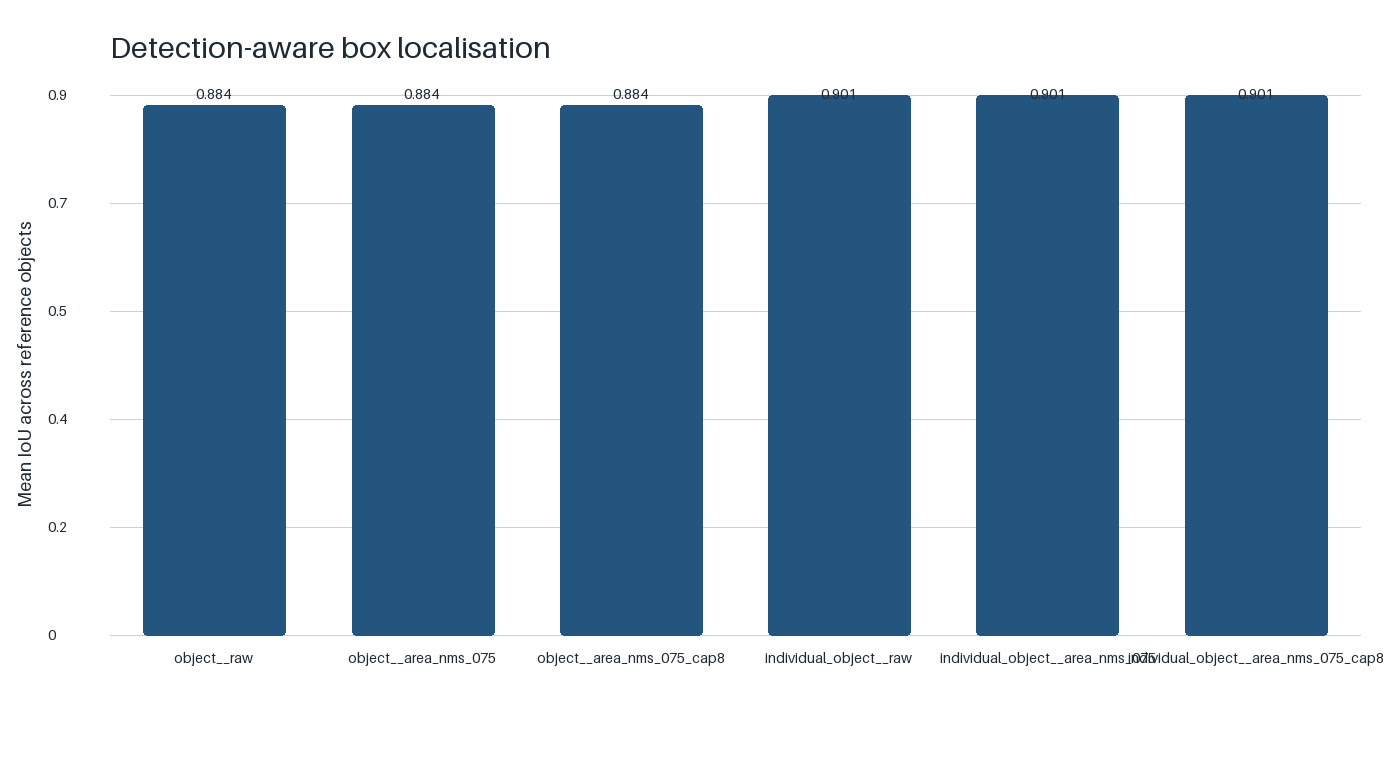

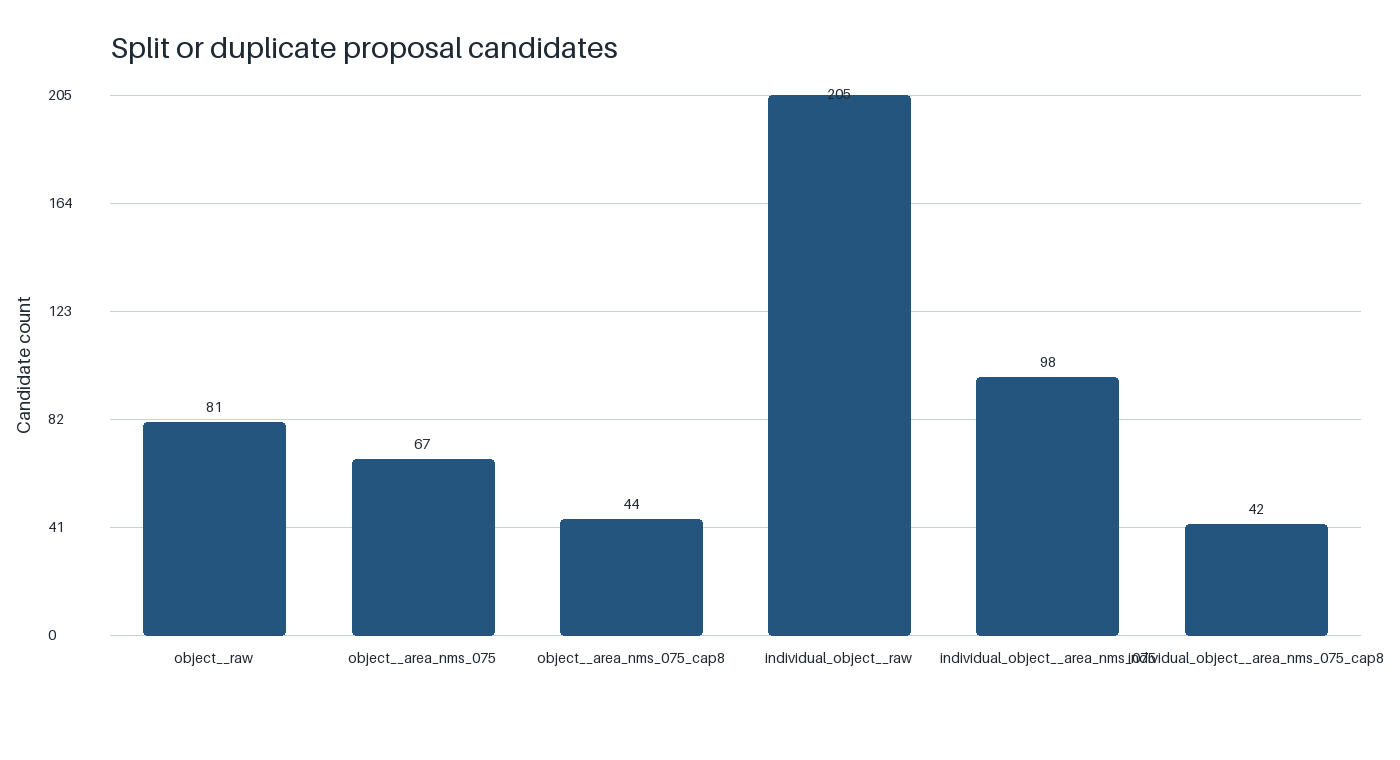

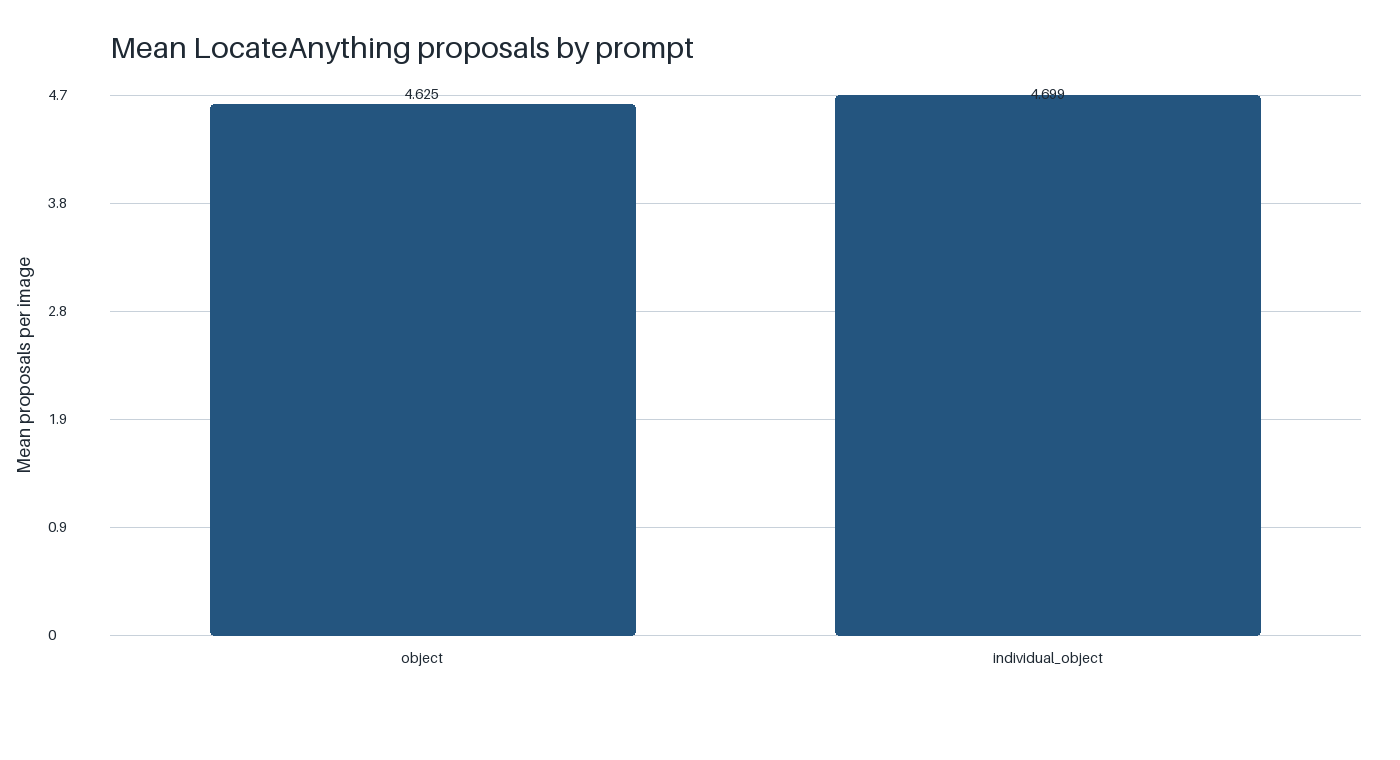

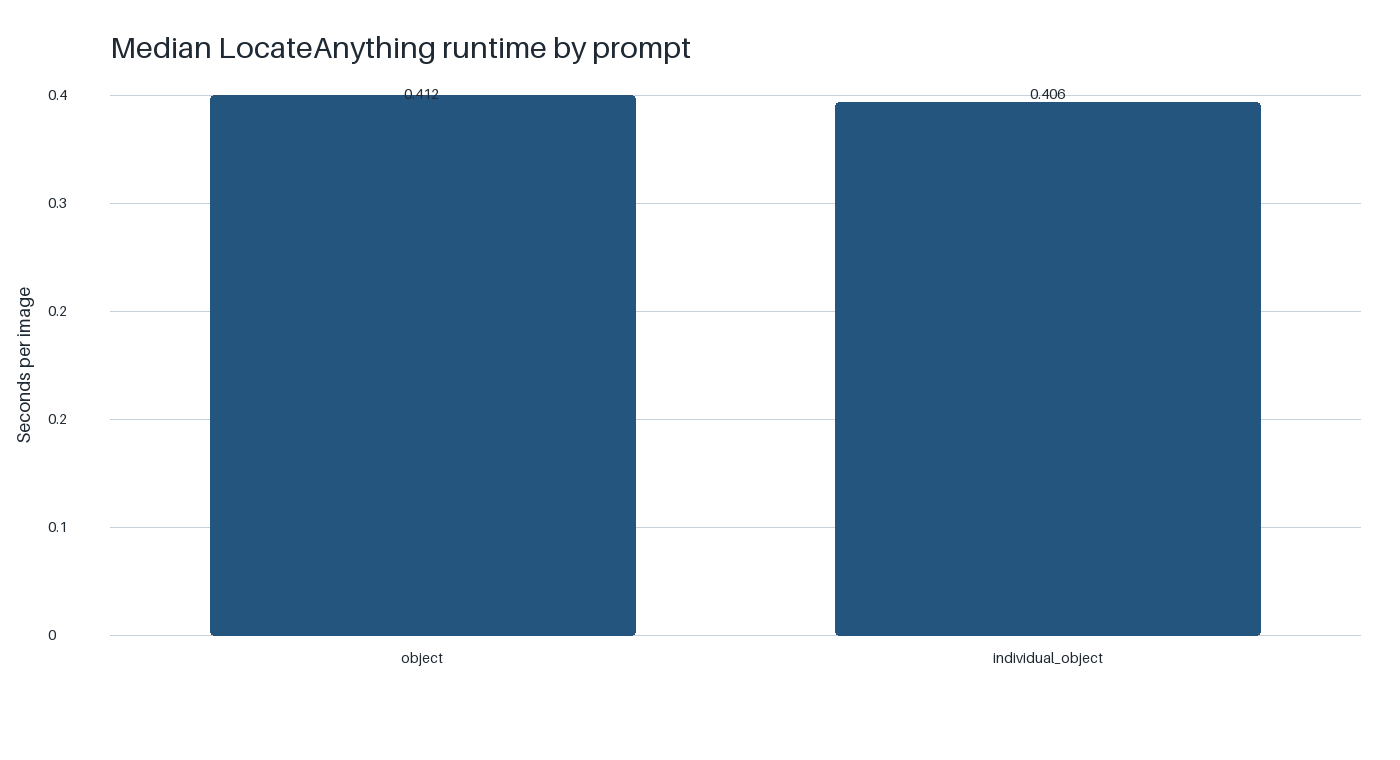

In [5]:
safe_root = OUTPUT_ROOT / "evaluation" / "safe"
summary = pd.read_csv(safe_root / "prompt_policy_summary.csv")
operational = pd.read_csv(safe_root / "prompt_operational_summary.csv")
repeatability = pd.read_csv(safe_root / "prompt_repeatability.csv")

display(summary.sort_values("f2_at_0_50", ascending=False))
display(operational)
display(repeatability)
display(DisplayImage(filename=str(safe_root / "prompt_policy_f2.png")))
display(DisplayImage(filename=str(safe_root / "complete_detection_rate.png")))
display(DisplayImage(filename=str(safe_root / "missed_objects.png")))
display(DisplayImage(filename=str(safe_root / "detection_aware_mean_iou.png")))
display(DisplayImage(filename=str(safe_root / "split_or_duplicate_candidates.png")))
display(DisplayImage(filename=str(safe_root / "mean_proposals_by_prompt.png")))
display(DisplayImage(filename=str(safe_root / "median_runtime_by_prompt.png")))

## Private visual review

The following panels show the same fixed 20-image selection for each prompt. Supplied reference boxes are thin green outlines. LocateAnything proposals are wider red outlines. Green drawn over red makes close matches visible in both colours. The panels are a visual diagnostic for missing, duplicate, merged, loose, background, and partial-object boxes. The success panel shows cases with no missed or extra boxes. The failure panel deliberately shows the most difficult cases and must not be presented as evidence of a fully automatic detector. These panels do not replace the evaluator metrics. They contain RGB images and remain in private Kaggle output.

In [6]:
example_root = OUTPUT_ROOT / "evaluation" / "private" / "prompt_examples"
for prompt_key, _prompt in PROMPT_CANDIDATES:
    for policy_key in POSTPROCESSING_POLICIES:
        display(DisplayImage(filename=str(example_root / f"{prompt_key}_{policy_key}_proposal_examples.png")))
for panel_name in ("selected_successes.png", "selected_failures.png"):
    panel_path = example_root / panel_name
    if panel_path.is_file():
        display(DisplayImage(filename=str(panel_path)))

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

<IPython.core.display.Image object>

## Selected DS1 configuration

In [7]:
selection = json.loads((safe_root / "selected_prompt.json").read_text(encoding="utf-8"))
checks = pd.read_csv(safe_root / "completion_checks.csv")
display(pd.DataFrame([selection["selected"]]))
display(checks)
if not checks["passed"].astype(str).str.lower().isin(["true", "1"]).all():
    raise RuntimeError("Notebook 04.3 has an incomplete run or failed integrity check")

print(selection["selection_rule"])
print("This DS1 choice must be confirmed unchanged on DS2 before it is treated as frozen.")

,candidate_key,complete_detection_rate,detection_aware_mean_iou,f1_at_0_50,f2_at_0_50,mean_matched_iou,postprocessing_policy,precision_at_0_50,prompt,prompt_key,proposal_count,recall_at_0_50,recall_at_0_75
0,individual_object__area_nms_075_cap8,0.918,0.900626,0.967603,0.964202,0.936252,area_nms_075_cap8,0.973325,individual object,individual_object,7610,0.961948,0.922338


,check,passed
0,all prompt candidates completed,True
1,candidate files locked before evaluation,True
2,all candidate policies evaluated,True
3,selected configuration reserved for unchanged ...,True
4,Notebook 04.1 object baseline reused,True
5,LocateAnything model loaded at most once,True
6,"one-image, pilot, repeat and full gates completed",True
7,aggregate-only ClearML evidence prepared,True


Maximise F2 at box IoU 0.50, then recall at IoU 0.75, detection-aware mean IoU, complete-detection rate, F1, precision, and lower proposal count.
This DS1 choice must be confirmed unchanged on DS2 before it is treated as frozen.


## Safe ClearML finalisation

Tracking starts only after the experiment and artifact manifests are complete. The finaliser uses a strict aggregate allowlist and a wall-time limit. It rejects private identifiers, boxes, masks, RGB paths, raw responses, and credentials. A ClearML problem cannot invalidate or block the completed model run.

In [8]:
def read_kaggle_secret(name: str) -> str | None:
    if EXECUTION_ENVIRONMENT != "kaggle":
        return os.environ.get(name)
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name) or None
    except Exception:
        return None


tracking_mode = os.getenv(
    "VPI_TRACKING_MODE", "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
).strip().lower()
tracking_environment = os.environ.copy()
if tracking_mode == "online":
    credentials = {
        name: read_kaggle_secret(name)
        for name in ("CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY")
    }
    if all(credentials.values()):
        tracking_environment.update(credentials)
        tracking_environment.setdefault("CLEARML_API_HOST", "https://api.clear.ml")
        tracking_environment.setdefault("CLEARML_WEB_HOST", "https://app.clear.ml")
        tracking_environment.setdefault("CLEARML_FILES_HOST", "https://files.clear.ml")
    else:
        tracking_mode = "disabled"

receipt = OUTPUT_ROOT / "evaluation" / "clearml_receipt.json"
tracking_command = [
    sys.executable,
    str(CODE_ROOT / "scripts/finalize_ds1_locateanything_prompt_freeze_clearml.py"),
    "--safe-root", str(safe_root),
    "--receipt", str(receipt),
    "--mode", tracking_mode,
    "--task-name", "ds1-locateanything-prompt-freeze",
    "--tag", "notebook-04.3", "--tag", "ds1", "--tag", "prompt-freeze", "--tag", "kaggle",
]
try:
    subprocess.run(
        tracking_command,
        env=tracking_environment,
        check=False,
        capture_output=True,
        text=True,
        timeout=240,
    )
except subprocess.TimeoutExpired:
    print("ClearML finalisation reached its wall-time limit after the experiment completed.")
if not receipt.is_file():
    receipt.write_text(json.dumps({"status": "not_recorded", "task_id": None}) + "\n", encoding="utf-8")
display(pd.DataFrame([json.loads(receipt.read_text(encoding="utf-8"))]))

,mode,safe_manifest_sha256,schema_version,stage,status,task_id
0,disabled,6b005fc814f320d0f658f9281dce28225be220b68dce8e...,1,notebook_04_3_clearml_finalisation,disabled,None


## Final output check

In [9]:
manifest = json.loads((safe_root / "artifact_manifest.json").read_text(encoding="utf-8"))
run_record = json.loads((safe_root / "run_record.json").read_text(encoding="utf-8"))
final_summary = {
    "status": run_record["status"],
    "selected candidate": run_record["selected_candidate"],
    "evaluated images per prompt": run_record["image_count"],
    "candidate and policy combinations": run_record["candidate_count"],
    "safe artifact count": manifest["artifact_count"],
    "baseline reused": run_record["baseline_reused"],
    "model loads in this run": run_record["model_load_count"],
}
display(pd.DataFrame([final_summary]))

,status,selected candidate,evaluated images per prompt,candidate and policy combinations,safe artifact count,baseline reused,model loads in this run
0,completed,individual_object__area_nms_075_cap8,2000,6,15,True,1


## Build compact download bundles

The packager validates the safe manifest before creating three deterministic archives. Repository evidence contains aggregate safe outputs. Review evidence contains the private prompt panels. Downstream input contains only the selected prompt record and selected proposal file required by the next stage. Credentials and Kaggle logs are excluded.

In [10]:
bundle_root = (
    Path("/kaggle/working/notebook04_3_bundles")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook04_3_bundles"
)
verification_path = bundle_root / "ds1-locateanything-prompt-freeze-verification.json"
if not verification_path.is_file():
    # Keep aggregate, private-review, and downstream files in separate archives.
    subprocess.run(
        [
            sys.executable,
            str(CODE_ROOT / "scripts/package_kaggle_stage_output.py"),
            "--stage-root", str(OUTPUT_ROOT / "evaluation"),
            "--output-root", str(bundle_root),
            "--stage-name", "ds1-locateanything-prompt-freeze",
            "--review-path", "private/prompt_examples",
            "--review-path", "clearml_receipt.json",
            "--downstream-path", "downstream",
        ],
        check=True,
        text=True,
    )
bundle_verification = json.loads(verification_path.read_text(encoding="utf-8"))
display(pd.DataFrame(bundle_verification["archives"]))
print(f"Compact downloads: {bundle_root}")

{"archives": [{"path": "ds1-locateanything-prompt-freeze-repository-evidence.zip", "sha256": "9552945386bb577289ef3d00da14e71b1deeaeb9384d660c5d3bd20059a5c6e0", "size_bytes": 145547, "source_file_count": 16}, {"path": "ds1-locateanything-prompt-freeze-review-evidence.zip", "sha256": "a794ee49419e140c3ca9db3dcf32450ad03d67f7ff12ed39c053a8dcd1701b52", "size_bytes": 10135594, "source_file_count": 10}, {"path": "ds1-locateanything-prompt-freeze-downstream-input.zip", "sha256": "d504c37c9c8552362c68a583071ee2ba936f5fe284d24727ffc77f29c1db685f", "size_bytes": 292048, "source_file_count": 3}], "downstream_file_count": 3, "review_file_count": 10, "safe_file_count": 16, "safe_manifest_sha256": "6b005fc814f320d0f658f9281dce28225be220b68dce8ed1025a50b4c70a2c4a", "schema_version": 1, "stage": "ds1-locateanything-prompt-freeze", "status": "completed"}


,path,sha256,size_bytes,source_file_count
0,ds1-locateanything-prompt-freeze-repository-ev...,9552945386bb577289ef3d00da14e71b1deeaeb9384d66...,145547,16
1,ds1-locateanything-prompt-freeze-review-eviden...,a794ee49419e140c3ca9db3dcf32450ad03d67f7ff12ed...,10135594,10
2,ds1-locateanything-prompt-freeze-downstream-in...,d504c37c9c8552362c68a583071ee2ba936f5fe284d247...,292048,3


Compact downloads: /kaggle/working/notebook04_3_bundles


## Next use

The chosen prompt and postprocessing policy become an unchanged input to DS2. The next confirmation run must report proposal precision, recall, complete-detection rate, SAM mask quality, DINOv2 ranking results, B0 and P1 results, and multi-view consistency without another DS2-based tuning step. The automatic and assisted routes remain separate in the report.